<a href="https://colab.research.google.com/github/ripon-cse24/99_days_of_coding_MLOps_With_CPC/blob/main/phase-1/day-014/day-014.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats

In [4]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [5]:
data = pd.read_csv("/content/Wine dataset.csv")

In [6]:
data.head()

,class,Alcohol,Malic acid,Ash,Alcalinity of ash,Magnesium,Total phenols,Flavanoids,Nonflavanoid phenols,Proanthocyanins,Color intensity,Hue,OD280/OD315 of diluted wines,Proline
0,1,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065
1,1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050
2,1,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185
3,1,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480
4,1,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735


In [7]:
data.tail()

,class,Alcohol,Malic acid,Ash,Alcalinity of ash,Magnesium,Total phenols,Flavanoids,Nonflavanoid phenols,Proanthocyanins,Color intensity,Hue,OD280/OD315 of diluted wines,Proline
173,3,13.71,5.65,2.45,20.5,95,1.68,0.61,0.52,1.06,7.7,0.64,1.74,740
174,3,13.40,3.91,2.48,23.0,102,1.80,0.75,0.43,1.41,7.3,0.70,1.56,750
175,3,13.27,4.28,2.26,20.0,120,1.59,0.69,0.43,1.35,10.2,0.59,1.56,835
176,3,13.17,2.59,2.37,20.0,120,1.65,0.68,0.53,1.46,9.3,0.60,1.62,840
177,3,14.13,4.10,2.74,24.5,96,2.05,0.76,0.56,1.35,9.2,0.61,1.60,560


In [8]:
data.shape

(178, 14)

In [9]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 14 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   class                         178 non-null    int64  
 1   Alcohol                       178 non-null    float64
 2   Malic acid                    178 non-null    float64
 3   Ash                           178 non-null    float64
 4   Alcalinity of ash             178 non-null    float64
 5   Magnesium                     178 non-null    int64  
 6   Total phenols                 178 non-null    float64
 7   Flavanoids                    178 non-null    float64
 8   Nonflavanoid phenols          178 non-null    float64
 9   Proanthocyanins               178 non-null    float64
 10  Color intensity               178 non-null    float64
 11  Hue                           178 non-null    float64
 12  OD280/OD315 of diluted wines  178 non-null    float64
 13  Proli

In [14]:
data.describe()

,class,Alcohol,Malic acid,Ash,Alcalinity of ash,Magnesium,Total phenols,Flavanoids,Nonflavanoid phenols,Proanthocyanins,Color intensity,Hue,OD280/OD315 of diluted wines,Proline
count,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000
mean,1.938202,13.000618,2.336348,2.366517,19.494944,99.741573,2.295112,2.029270,0.361854,1.590899,5.058090,0.957449,2.611685,746.893258
std,0.775035,0.811827,1.117146,0.274344,3.339564,14.282484,0.625851,0.998859,0.124453,0.572359,2.318286,0.228572,0.709990,314.907474
min,1.000000,11.030000,0.740000,1.360000,10.600000,70.000000,0.980000,0.340000,0.130000,0.410000,1.280000,0.480000,1.270000,278.000000
25%,1.000000,12.362500,1.602500,2.210000,17.200000,88.000000,1.742500,1.205000,0.270000,1.250000,3.220000,0.782500,1.937500,500.500000
50%,2.000000,13.050000,1.865000,2.360000,19.500000,98.000000,2.355000,2.135000,0.340000,1.555000,4.690000,0.965000,2.780000,673.500000
75%,3.000000,13.677500,3.082500,2.557500,21.500000,107.000000,2.800000,2.875000,0.437500,1.950000,6.200000,1.120000,3.170000,985.000000
max,3.000000,14.830000,5.800000,3.230000,30.000000,162.000000,3.880000,5.080000,0.660000,3.580000,13.000000,1.710000,4.000000,1680.000000


In [15]:
data.isnull().sum()

,0
class,0
Alcohol,0
Malic acid,0
Ash,0
Alcalinity of ash,0
Magnesium,0
Total phenols,0
Flavanoids,0
Nonflavanoid phenols,0
Proanthocyanins,0


In [16]:
data['Malic acid'].unique()

array([1.71, 1.78, 2.36, 1.95, 2.59, 1.76, 1.87, 2.15, 1.64, 1.35, 2.16,
       1.48, 1.73, 1.81, 1.92, 1.57, 1.59, 3.1 , 1.63, 3.8 , 1.86, 1.6 ,
       2.05, 1.77, 1.72, 1.9 , 1.68, 1.5 , 1.66, 1.83, 1.53, 1.8 , 1.65,
       3.99, 3.84, 1.89, 3.98, 4.04, 3.59, 2.02, 1.75, 1.67, 1.7 , 1.97,
       1.43, 0.94, 1.1 , 1.36, 1.25, 1.13, 1.45, 1.21, 1.01, 1.17, 1.19,
       1.61, 1.51, 1.09, 1.88, 0.9 , 2.89, 0.99, 3.87, 0.92, 3.86, 0.89,
       0.98, 2.06, 1.33, 2.83, 1.99, 1.52, 2.12, 1.41, 1.07, 3.17, 2.08,
       1.34, 2.45, 2.55, 1.29, 3.74, 2.43, 2.68, 0.74, 1.39, 1.47, 3.43,
       2.4 , 4.43, 5.8 , 4.31, 2.13, 4.3 , 2.99, 2.31, 3.55, 1.24, 2.46,
       4.72, 5.51, 2.96, 2.81, 2.56, 4.95, 3.88, 3.57, 5.04, 4.61, 3.24,
       3.9 , 3.12, 2.67, 3.3 , 5.19, 4.12, 3.03, 3.83, 3.26, 3.27, 3.45,
       2.76, 4.36, 3.7 , 3.37, 2.58, 4.6 , 2.39, 2.51, 5.65, 3.91, 4.28,
       4.1 ])

In [17]:
data['Malic acid'].value_counts()

,count
Malic acid,
1.73,7
1.81,4
1.67,4
1.35,3
1.90,3
...,...
2.51,1
5.65,1
3.91,1


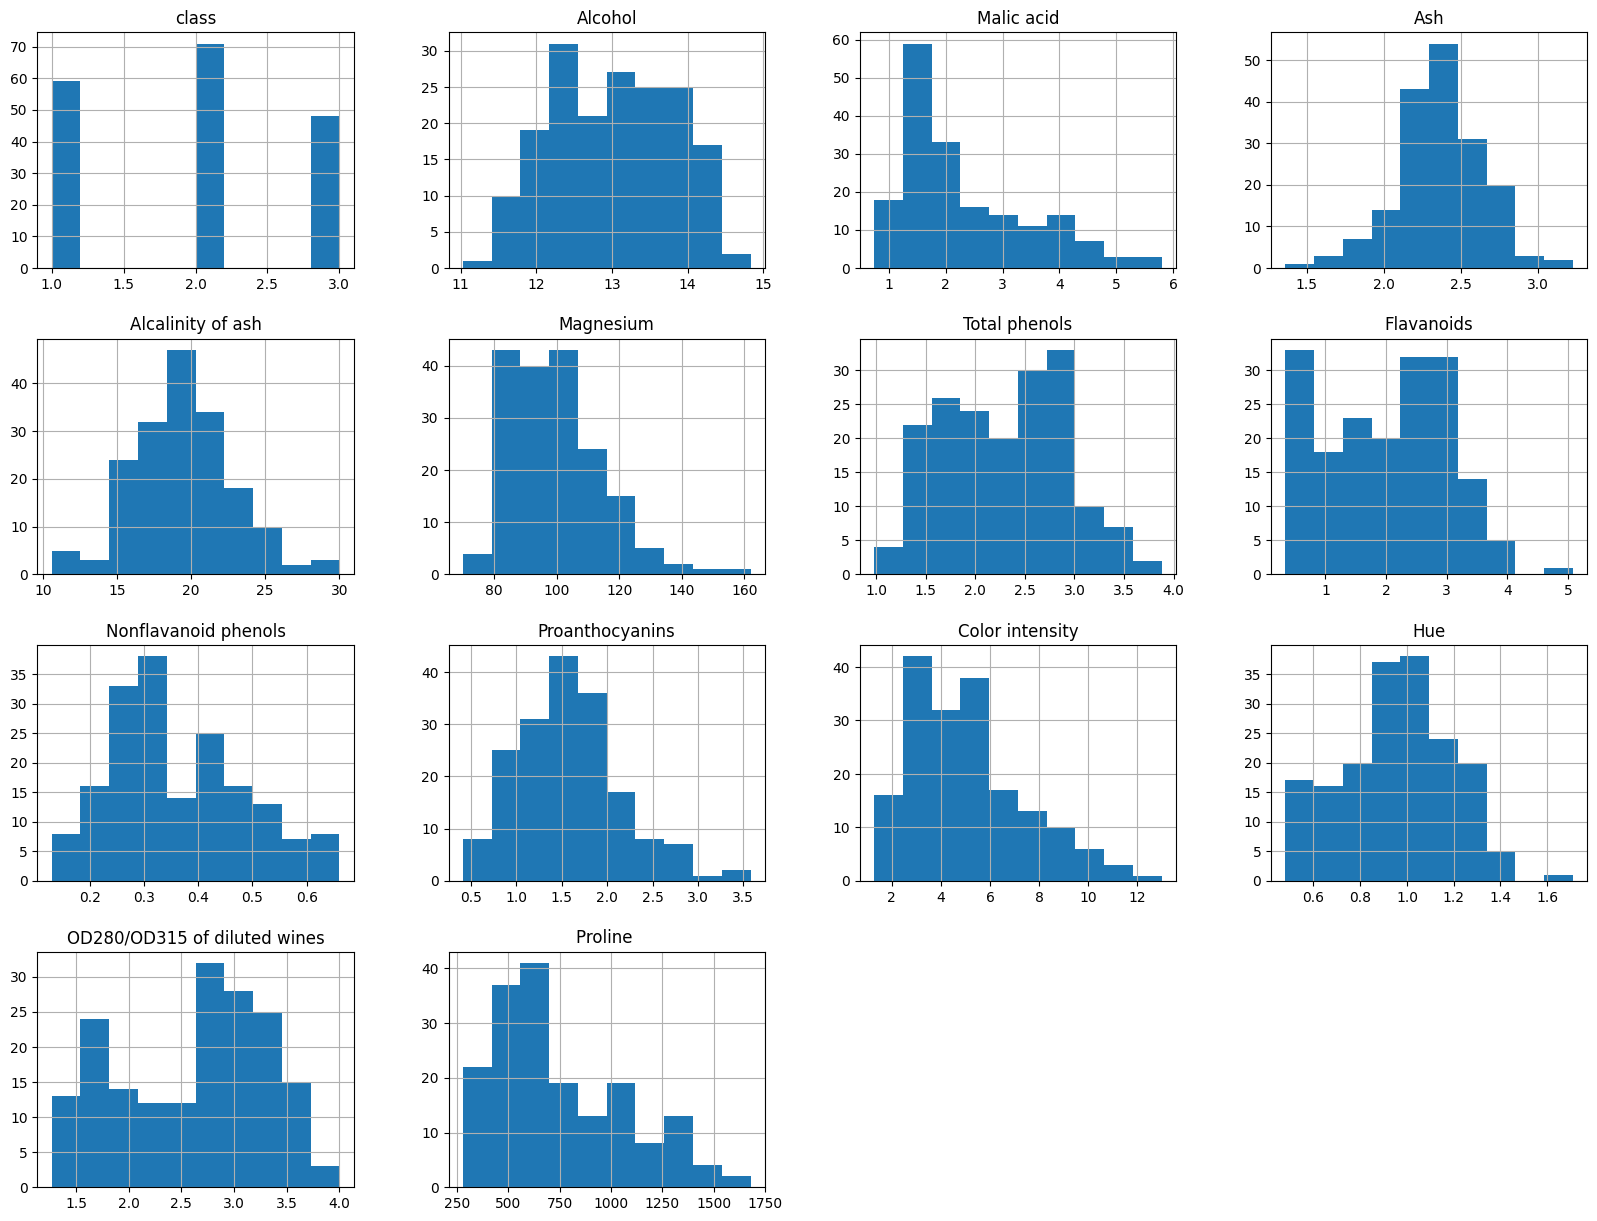

In [18]:
data.hist(figsize=(20,15))
plt.show()

In [19]:
data.columns

Index(['class', 'Alcohol', 'Malic acid', 'Ash', 'Alcalinity of ash',
       'Magnesium', 'Total phenols', 'Flavanoids', 'Nonflavanoid phenols',
       'Proanthocyanins', 'Color intensity', 'Hue',
       'OD280/OD315 of diluted wines', 'Proline '],
      dtype='object')

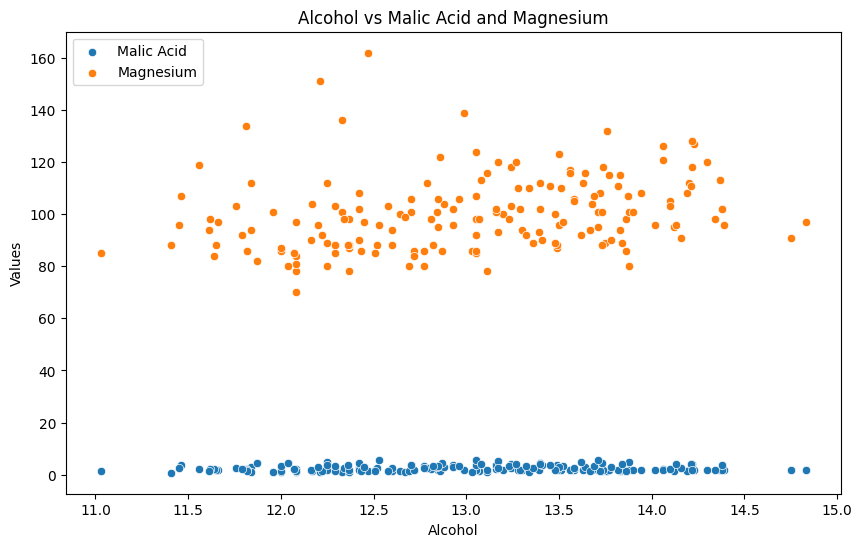

In [23]:
plt.figure(figsize=(10, 6))

sns.scatterplot(data=data, x='Alcohol', y='Malic acid', label='Malic Acid')

sns.scatterplot(data=data, x='Alcohol', y='Magnesium', label='Magnesium')

plt.title('Alcohol vs Malic Acid and Magnesium')
plt.xlabel('Alcohol')
plt.ylabel('Values')
plt.legend(loc='upper left')
plt.show()

In [24]:
data[['Alcohol', 'Malic acid', 'Magnesium']].corr()

,Alcohol,Malic acid,Magnesium
Alcohol,1.000000,0.094397,0.270798
Malic acid,0.094397,1.000000,-0.054575
Magnesium,0.270798,-0.054575,1.000000


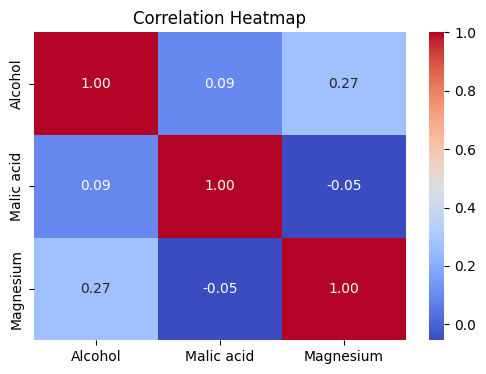

In [25]:
plt.figure(figsize=(6, 4))

sns.heatmap(
    data[['Alcohol', 'Malic acid', 'Magnesium']].corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')
plt.show()